# Homework

## Dataset
In this homework, we will use the 2026 lead-scoring dataset. Download it from [here](https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv).

Or you can do it with wget:

```wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv```

In this dataset our desired target for classification task will be ```converted``` variable - has the client signed up to the platform or not.

## Data preparation
- Check if the missing values are presented in the features.
- If there are missing values:
    - For categorical features, replace them with 'NA'
    - For numerical features, replace with with 0.0

In [1]:
import os
import pandas as pd

filename = "course_lead_scoring_2026.csv"
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"

if not os.path.exists(filename):
    !wget {url} -O {filename}

df = pd.read_csv(filename)
df.head()

--2026-10-15 11:26:57--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘course_lead_scoring_2026.csv’

course_lead_scoring 100%[===================>] 272.21K  --.-KB/s    in 0.003s  

2026-10-15 11:26:57 (80.1 MB/s) - ‘course_lead_scoring_2026.csv’ saved [278746/278746]



,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [2]:
# Check the columns and their types
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [3]:
# Check for missing values
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [4]:
# Define the column lists
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['number_of_courses_viewed', 'annual_income', 'interaction_count', 'lead_score']

In [5]:
# Fill the gaps
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

In [6]:
# Check it worked
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

## Split the data
Split the data into 3 parts with these exact calls:

```
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
```

In [7]:
import numpy as np
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

## Question 1: ROC AUC feature importance
ROC AUC could also be used to evaluate feature importance of numerical variables.

Let's do that

- For each numerical variable, use it as score (aka prediction) and compute the AUC with the ```y``` variable as ground truth.
- Use the training dataset for that

If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. ```-df_train['balance']```)

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

- ```lead_score```
- ```number_of_courses_viewed```
- ```interaction_count```
- ```annual_income```

In [9]:
from sklearn.metrics import roc_auc_score

auc_scores = {}

for c in numerical:
    auc = roc_auc_score(y_train, df_train[c])

    # if the column ranks the wrong way round, flip it
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[c])

    auc_scores[c] = auc
    print(c, round(auc, 3))

print('\nAnswer:', max(auc_scores, key=auc_scores.get))

number_of_courses_viewed 0.723
annual_income 0.608
interaction_count 0.765
lead_score 0.788

Answer: lead_score


## Question 2: Training the model
Apply one-hot-encoding using ```DictVectorizer``` and train the logistic regression with these parameters:

```
LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
```

What's the AUC of this model on the validation dataset? (round to 3 digits)

- 0.532
- 0.632
- 0.732
- 0.832

In [11]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

# One-hot encoding
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

# Train the model with the homework's settings
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

# Predict probabilities on validation and score with AUC
y_pred = model.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, y_pred)
print('Answer:', round(auc, 3))

Answer: 0.732


## Question 3: Precision and Recall
Now let's compute precision and recall for our model.

- Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
- For each threshold, compute precision and recall
- Plot them

At which threshold precision and recall curves intersect? Ignore thresholds at which both metrics are zero, and choose the threshold with the smallest absolute difference between precision and recall.

- 0.43
- 0.63
- 0.73
- 0.83

In [19]:
import matplotlib.pyplot as plt

# Step 1: count the confusion table at every threshold
scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    scores.append((t, tp, fp, fn, tn))

columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

In [20]:
# Step 2: precision and recall
df_scores['p'] = df_scores.tp / (df_scores.tp + df_scores.fp)
df_scores['r'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['p'] = df_scores['p'].fillna(0)

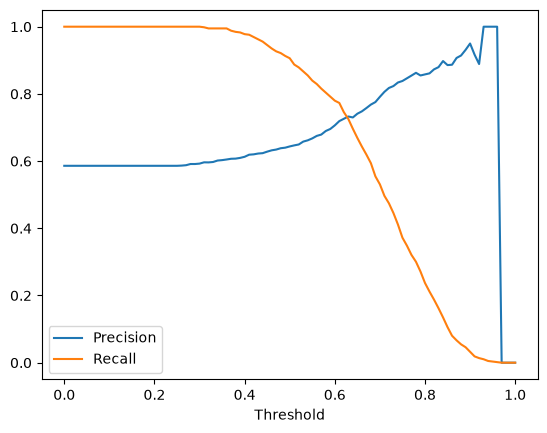

In [21]:
# Step 3: plot them
plt.plot(df_scores.threshold, df_scores['p'], label='Precision')
plt.plot(df_scores.threshold, df_scores['r'], label='Recall')
plt.xlabel('Threshold')
plt.legend()
plt.show()

In [22]:
# Step 4: find where they cross
valid = df_scores[(df_scores.p > 0) | (df_scores.r > 0)]
diff = (valid.p - valid.r).abs()
best = valid.loc[diff.idxmin(), 'threshold']

print('Answer:', round(best, 2))

Answer: 0.63


## Question 4: F1 score
Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:

$$F_1 = 2 \cdot \cfrac{P \cdot R}{P + R}$$

Where $P$ is precision and $R$ is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?

- 0.21
- 0.41
- 0.61
- 0.81

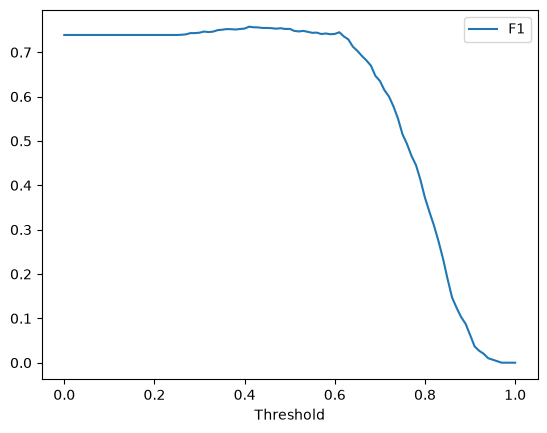

Answer: 0.41


In [23]:
# F1 for every threshold
df_scores['f1'] = 2 * (df_scores.p * df_scores.r) / (df_scores.p + df_scores.r)
df_scores['f1'] = df_scores['f1'].fillna(0)

# Plot it
plt.plot(df_scores.threshold, df_scores['f1'], label='F1')
plt.xlabel('Threshold')
plt.legend()
plt.show()

# Find the threshold where F1 is highest
best = df_scores.loc[df_scores.f1.idxmax(), 'threshold']
print('Answer:', round(best, 2))

## Question 5: 5-Fold CV
Use the ```KFold``` class from Scikit-Learn to evaluate our model on 5 different folds:

```
KFold(n_splits=5, shuffle=True, random_state=1)
```

- Iterate over different folds of ```df_full_train```
- Split the data into train and validation
- Train the model on train with these parameters: ```LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)```
- Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?

- 0.001
- 0.007
- 0.013
- 0.060

In [25]:
from sklearn.model_selection import KFold

# Helper functions
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model

def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

# 5-fold cross-validation
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train_cv = df_full_train.iloc[train_idx]
    df_val_cv = df_full_train.iloc[val_idx]

    y_train_cv = df_train_cv.converted.values
    y_val_cv = df_val_cv.converted.values

    dv, model = train(df_train_cv, y_train_cv, C=1.0)
    y_pred_cv = predict(df_val_cv, dv, model)

    auc = roc_auc_score(y_val_cv, y_pred_cv)
    scores.append(auc)

print('Scores:', np.round(scores, 3))
print('Mean:', round(np.mean(scores), 3))
print('\nAnswer (std):', round(np.std(scores), 3))

Scores: [0.731 0.73  0.736 0.741 0.721]
Mean: 0.732

Answer (std): 0.007


## Question 6: Hyperparameter Tuning
Now let's use 5-Fold cross-validation to find the best parameter ```C```

- Iterate over the following ```C``` values: ```[0.000001, 0.001, 1]```
- Initialize ```KFold``` with the same parameters as previously
- Use these parameters for the model: ```LogisticRegression(solver='liblinear', C=C, max_iter=1000)```
- Compute the mean ROC AUC as well as the std (round the mean and std to 3 decimal digits).

Which ```C``` leads to the best mean ROC AUC?

- 0.000001
- 0.001
- 1

If you have ties, select the score with the lowest std. If you still have ties, select the smallest ```C```.

In [27]:
results = []

for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train_cv = df_full_train.iloc[train_idx]
        df_val_cv = df_full_train.iloc[val_idx]

        y_train_cv = df_train_cv.converted.values
        y_val_cv = df_val_cv.converted.values

        dv, model = train(df_train_cv, y_train_cv, C=C)
        y_pred_cv = predict(df_val_cv, dv, model)

        auc = roc_auc_score(y_val_cv, y_pred_cv)
        scores.append(auc)

    mean = round(np.mean(scores), 3)
    std = round(np.std(scores), 3)
    results.append((C, mean, std))

    print('C=%s %.3f +- %.3f' % (C, mean, std))

# Pick the best C: highest mean, then lowest std, then smallest C
df_results = pd.DataFrame(results, columns=['C', 'mean', 'std'])
df_results = df_results.sort_values(by=['mean', 'std', 'C'], ascending=[False, True, True])

print('\nAnswer:', df_results.iloc[0]['C'])

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007

Answer: 0.001


## Submit the results
- Submit your results here: https://courses.datatalks.club/ml-zoomcamp-2026/homework/hw04
- The numerical options are calculated from the pinned 2026 release. Use the value that matches your calculation; do not choose a merely close value.